In [1]:
# Import required libraries for data modeling and evaluation
import joblib
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier

# Load the preprocessed dataset from the saved CSV file
df_encoded = pd.read_csv('../data/processed/car_insurance_encoded.csv')

# Verify that the dataset was loaded successfully and check its dimensions (rows and columns)
print("Data loaded successfully, shape:", df_encoded.shape)

Data loaded successfully, shape: (10000, 23)


In [2]:
# Separate features (X) from the target variable (y) by dropping 'id' and 'outcome' columns
X = df_encoded.drop(columns=['id', 'outcome'])
y = df_encoded['outcome']

# Split the dataset into training and testing sets (80/20 ratio) while maintaining class balance using stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Verify the shapes of the split datasets
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (8000, 21)
Testing data shape: (2000, 21)


In [3]:
from sklearn.preprocessing import StandardScaler

# Scale the features to help Logistic Regression converge properly
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define baseline models for comparison (increased max_iter for Logistic Regression)
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

baseline_results = {}

# Train each model and calculate accuracy (using scaled data for Logistic Regression)
for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
    acc = accuracy_score(y_test, y_pred)
    baseline_results[name] = acc
    print(f"Model: {name} | Accuracy: {acc:.4f}")

Model: Logistic Regression | Accuracy: 0.8375
Model: Decision Tree | Accuracy: 0.7820
Model: Random Forest | Accuracy: 0.8185
Model: Gradient Boosting | Accuracy: 0.8450


In [4]:
# Create a copy of the training and testing sets to work safely
X_train_adv = X_train.copy()
X_test_adv = X_test.copy()

# Create a new feature: accidents per violation ratio (adding 1 to prevent division by zero)
X_train_adv['accidents_per_violation'] = X_train_adv['past_accidents'] / (X_train_adv['speeding_violations'] + 1)
X_test_adv['accidents_per_violation'] = X_test_adv['past_accidents'] / (X_test_adv['speeding_violations'] + 1)

# Create a new feature: interaction between annual mileage and speeding violations (traffic exposure index)
X_train_adv['mileage_violation_interaction'] = X_train_adv['annual_mileage'] * (X_train_adv['speeding_violations'] + 1)
X_test_adv['mileage_violation_interaction'] = X_test_adv['annual_mileage'] * (X_test_adv['speeding_violations'] + 1)

# Verify the new shape of the dataset after adding advanced features
print("Advanced features added successfully. New shape:", X_train_adv.shape)

Advanced features added successfully. New shape: (8000, 23)


In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

# Define the hyperparameter grid for tuning the Gradient Boosting model
param_grid_clean = {
    'n_estimators': [150, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3],
    'subsample': [0.8, 1.0]
}

# Initialize GridSearchCV (set n_jobs=1 to avoid multiprocessing pickling issues on Windows notebooks)
gb_clean_grid = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid_clean,
    cv=5,
    scoring='f1',
    n_jobs=1,  # Safe execution mode for Jupyter on Windows
    verbose=1
)

print("Searching for the optimal model parameters...")
# Fit the grid search to the advanced training data
gb_clean_grid.fit(X_train_adv, y_train)

# Extract the best estimator model and print the best parameters found
best_model_clean = gb_clean_grid.best_estimator_
print(f"\nBest parameters found: {gb_clean_grid.best_params_}")

Searching for the optimal model parameters...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best parameters found: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}


In [7]:
# Initialize the sub-models for the ensemble voting classifier
clf_rf = RandomForestClassifier(n_estimators=200, random_state=42)
clf_gb = best_model_clean  # Using the tuned Gradient Boosting model from GridSearchCV

# Create the Voting Classifier using 'soft' voting (averaging predicted probabilities for higher accuracy)
voting_model = VotingClassifier(
    estimators=[('rf', clf_rf), ('gb', clf_gb)],
    voting='soft'
)

# Train the ensemble voting model on the advanced feature dataset
voting_model.fit(X_train_adv, y_train)

# Make predictions on the test dataset using the voting model
y_pred_voting = voting_model.predict(X_test_adv)

# Evaluate and print the performance of the Voting Classifier model
print("=== Voting Classifier Performance Evaluation ===")
print(classification_report(y_test, y_pred_voting))
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_voting):.4f}")

=== Voting Classifier Performance Evaluation ===
              precision    recall  f1-score   support

         0.0       0.88      0.88      0.88      1373
         1.0       0.74      0.74      0.74       627

    accuracy                           0.84      2000
   macro avg       0.81      0.81      0.81      2000
weighted avg       0.84      0.84      0.84      2000

Accuracy Score: 0.8375


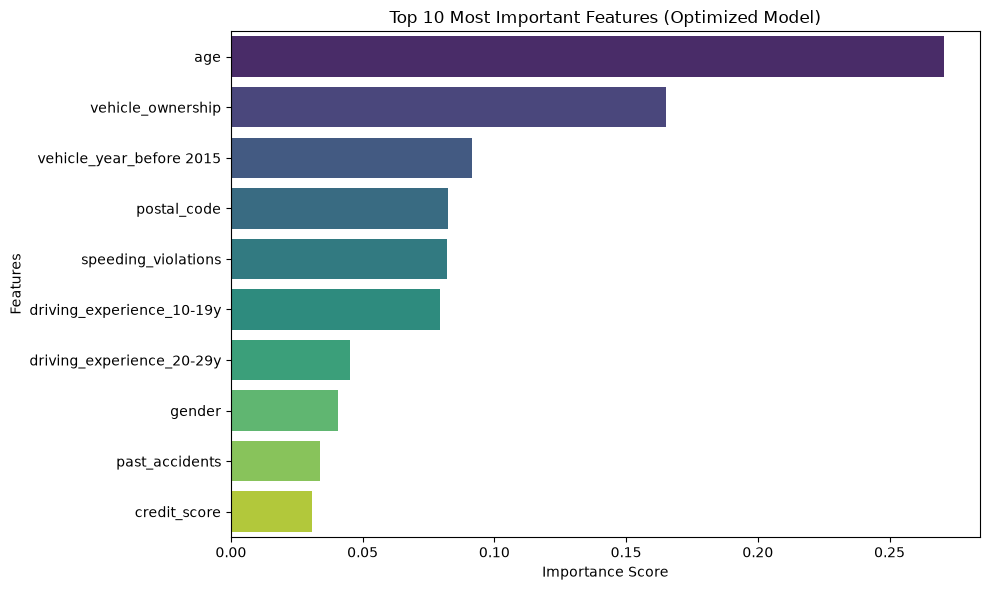

In [8]:
# Extract feature importances from the optimized Gradient Boosting model
importances_final = best_model_clean.feature_importances_

# Create a DataFrame to hold features and their importance scores, then sort them
feature_importance_final_df = pd.DataFrame({
    'Feature': X_train_adv.columns,
    'Importance': importances_final
}).sort_values(by='Importance', ascending=False)

# Plot the top 10 most influential features using Seaborn (fixed for modern versions)
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=feature_importance_final_df.head(10), 
    hue='Feature', 
    palette='viridis', 
    legend=False
)

plt.title('Top 10 Most Important Features (Optimized Model)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

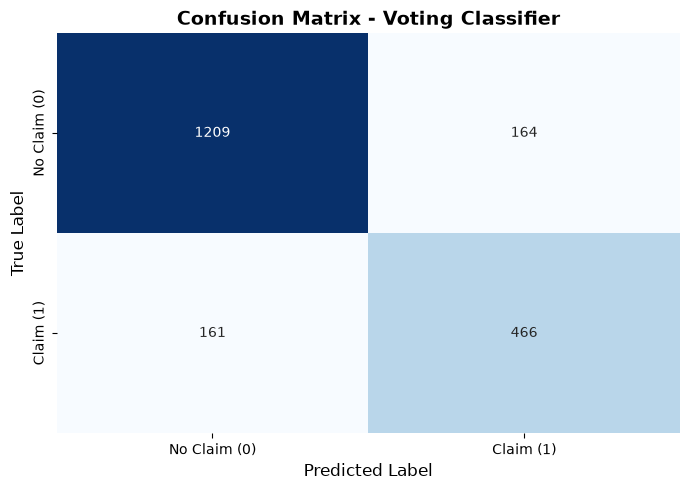

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_voting)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Claim (0)', 'Claim (1)'],
            yticklabels=['No Claim (0)', 'Claim (1)'])
plt.title('Confusion Matrix - Voting Classifier', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

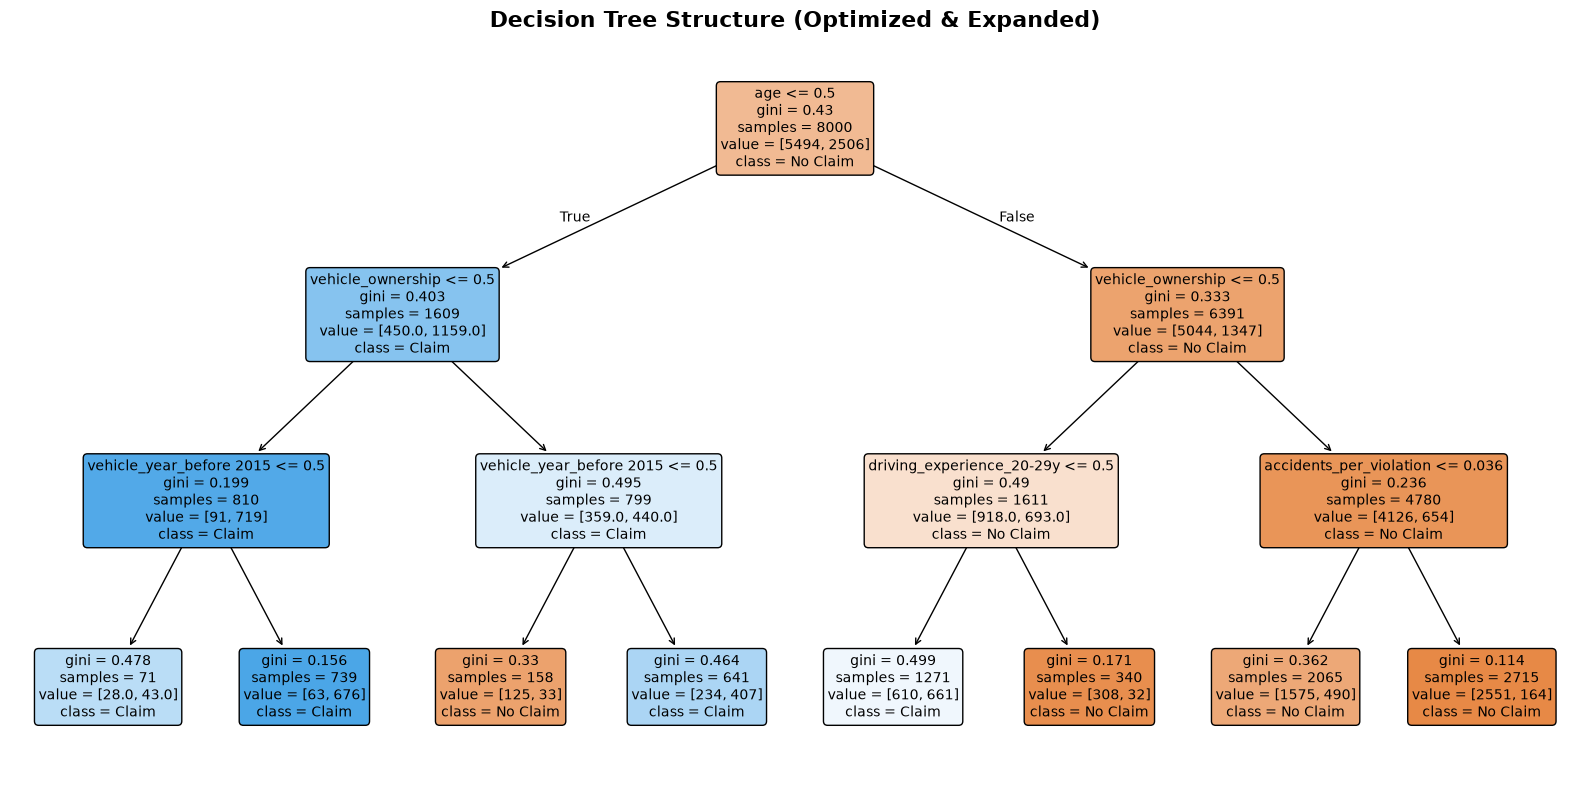

In [12]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Reduce the tree depth to 3 and provide a wide canvas for the plot
sample_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
sample_tree.fit(X_train_adv, y_train)

# Very wide figure size to prevent crowding and text overlapping
plt.figure(figsize=(16, 8)) 

plot_tree(
    sample_tree,
    feature_names=X_train_adv.columns,
    class_names=['No Claim', 'Claim'],
    filled=True,
    rounded=True,
    fontsize=10  # Increase font size slightly to make it readable
)

plt.title('Decision Tree Structure (Optimized & Expanded)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [13]:
# Ensure the 'models' directory exists before saving (creates it if missing)
os.makedirs('../models', exist_ok=True)

# Save the final trained Voting Classifier model to disk
joblib.dump(voting_model, '../models/best_voting_model.pkl')

print("The final model has been successfully saved in the 'models' directory.")

The final model has been successfully saved in the 'models' directory.
